# Flood Risk Exposure of Slovenian Settlements



| Layer | Type | Source | URL |
|-------|------|--------|-----|
| Settlements | Points | OpenStreetMap via Overpass API | https://overpass-api.de |
| Flood Hazard Zones | Polygons | INSPIRE WFS / eprostor.gov.si | https://storitve.eprostor.gov.si/ows-ins-wfs/wfs |
| Digital Elevation Model | Raster | EU-DEM v1.1 25m (Copernicus) | https://land.copernicus.eu/imagery-in-situ/eu-dem |
| Slovenian Water Bodies | Polygon (Lakes) & Line (Rivers) | OpenStreetMap via Overpass API | https://overpass-api.de/api/interpreter & https://overpass.karte.si/api/interpreter |
| Slovenia boundary | Polygon | GADM 4.1 | https://gadm.org |


**Summary of Workflow:**
1. Reproject all layers to EPSG:3794 (Slovenian national projection) & clip DEM
2. Zonal statistics as means to extract elevation per flood zone polygon
3. Spatial join to answer which settlements intersect flood zones
4. Risk classification by return period (10 / 100 / 500 yr)
5. Buffer analysis - 1 km proximity zone of settlement to flood areas


**Research Questions:**
1. Which Slovenian settlements are located within 1km of a flood area?
2. How does flood risk classify, based on settlements, across Slovenia?
3. Does the elevation of a settlement correspond to its flood risk?


In [1]:
# SSL fix for environments with outdated certificate bundles
    # to run on my specific laptop, this was required - may not be needed on other devices
import ssl, certifi
_orig = ssl.create_default_context
def _patched(*a, **kw):
    if not a and not any(k in kw for k in ('cafile','capath','cadata')):
        kw['cafile'] = certifi.where()
    return _orig(*a, **kw)
ssl.create_default_context = _patched
ssl._create_default_https_context = _patched

## Libraries

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import os, io, json as _json, zipfile, urllib.request, requests
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio
from rasterio.mask import mask as rio_mask
from rasterio.transform import from_bounds
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterstats import zonal_stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import contextily as ctx
from shapely.geometry import Point, Polygon
from shapely.geometry import LineString as LS

# Helper functino to fix issue with CRS standarization across datasets 
    # facilitates replication for each dataset
def as_gdf(df, crs='EPSG:3794'):
    return gpd.GeoDataFrame(df, geometry='geometry', crs=crs)

print('All imports OK')


All imports OK


## Data Acquisition

In [ ]:
# Slovenia national boundary 
# SOURCE: https://gadm.org/download_country.html

GADM_URL  = 'https://geodata.ucdavis.edu/gadm/gadm4.1/json/gadm41_SVN_0.json'

gadm_path = 'slovenia_boundary.geojson'

if not os.path.exists(gadm_path):
    print('Downloading Slovenia boundary')
    urllib.request.urlretrieve(GADM_URL, gadm_path)

slovenia = gpd.read_file(gadm_path).to_crs('EPSG:3794')

print('Boundary loaded, CRS:', 
      slovenia.crs)

print('Extent:', 
      np.round(slovenia.total_bounds, 
               0))


Boundary loaded, CRS: EPSG:3794
Extent: [375349.  32531. 621649. 193935.]


In [ ]:
# Settlements (Overpass API) 
# OpenStreetMap contributors
# SOURCE: https://overpass-api.de/api/interpreter

OVERPASS_URL = 'https://overpass-api.de/api/interpreter'

QUERY = """
[out:json][timeout:60];
(
  node["place"~"^(city|town|village)$"](45.4,13.3,46.9,16.6);
);
out body;
"""

settle_cache = 'settlements_svn.geojson'

if not os.path.exists(settle_cache):
    print('Querying Overpass API')
    resp = requests.get(
        OVERPASS_URL,
        params={'data': QUERY},
        timeout=90
    )
    resp.raise_for_status()
    elements = resp.json()['elements']
    records = [
        {'name': el['tags'].get('name',''), 
         'place': el['tags'].get('place',''),
         'geometry': Point(el['lon'], el['lat'])}
        for el in elements if 'tags' in el and 'lon' in el
    ]

    settlements_raw = gpd.GeoDataFrame(records, crs='EPSG:4326')

    print(f'  -> {len(settlements_raw)} nodes fetched from Overpass (bbox)')

else:
    settlements_raw = gpd.read_file(settle_cache)

    print(f'Loaded from cache: {len(settlements_raw)} settlements (pre-clip)')

# Clip from bounding box to Slovenia national boundary 
slov_4326 = slovenia.to_crs('EPSG:4326')  

settlements = gpd.clip(settlements_raw.to_crs('EPSG:4326'), 
                       slov_4326)

n_dropped = len(settlements_raw) - len(settlements)

print(f'{len(settlements)} settlements within Slovenia boundary'
      f'({n_dropped} cross-border nodes removed)')

if not os.path.exists(settle_cache):
    settlements.to_file(settle_cache, driver='GeoJSON')
    print(f'Cached to {settle_cache}')


Loaded from cache: 4731 settlements (pre-clip)
4731 settlements within Slovenia boundary(0 cross-border nodes removed)


In [ ]:
# Flood Hazard Zones — INSPIRE WFS 
# Slovenian national geoportal, EU Floods Directive layer
# SOURCE: https://storitve.eprostor.gov.si/ows-ins-wfs/wfs
# Layer: PS.FloodedArea

WFS_URL = (
    'https://storitve.eprostor.gov.si/ows-ins-wfs/wfs'
    '?SERVICE=WFS&VERSION=2.0.0&REQUEST=GetFeature'
    '&TYPENAMES=PS.FloodedArea&SRSNAME=EPSG:3794'
    '&outputFormat=application/json'
)

flood_cache = 'slovenia_flood_hazard.geojson'

if not os.path.exists(flood_cache):

    print('Retreivnig flood zones from INSPIRE WFS')
    
    flood_zones = gpd.read_file(WFS_URL)

    # Normalise column names (fix issue with name consistency error)
    col_map = {}

    for c in flood_zones.columns:
        lc = c.lower()
        if any(t in lc for t in ['return',
                                 'period',
                                 'recurrence']): col_map[c] = 'return_period_yr'
        elif any(t in lc for t in ['zone',
                                   'name',
                                   'river']):col_map[c] = 'flood_zone'
        
    flood_zones = flood_zones.rename(columns=col_map)

    if 'flood_zone' not in flood_zones.columns: flood_zones['flood_zone'] = 'Unknown'

    if 'return_period_yr' not in flood_zones.columns: flood_zones['return_period_yr'] = 100

    flood_zones[['geometry',
                 'flood_zone',
                 'return_period_yr']].to_file(flood_cache, 
                                              driver='GeoJSON')
    
    print(f'{len(flood_zones)} polygons cached')

else:
    flood_zones = gpd.read_file(flood_cache)

    print(f'Loaded from cache: {len(flood_zones)} polygons')

flood_zones = flood_zones.to_crs('EPSG:3794')

flood_zones['return_period_yr'] = pd.to_numeric(
    flood_zones.get('return_period_yr', 
                    100), 
                    errors='coerce').fillna(100)

print('Return periods:', 
      sorted(flood_zones['return_period_yr'].unique()))


Loaded from cache: 70 polygons
Return periods: [np.int32(10), np.int32(100), np.int32(500)]


In [6]:
# Water bodies (Overpass API (rivers, lakes)) 
# OpenStreetMap contributors

OVERPASS_MIRRORS = [
    'https://overpass-api.de/api/interpreter',
    'https://overpass.karte.si/api/interpreter',
]

# river/canals 
RIVER_QUERY = """
[out:json][timeout:60][maxsize:134217728];
way["waterway"~"^(river|canal)$"](45.4,13.3,46.9,16.6);
out geom;
"""

# water body polygons
LAKE_QUERY = """
[out:json][timeout:60][maxsize:134217728];
way["natural"="water"](45.4,13.3,46.9,16.6);
out geom;
"""

water_cache = 'water_bodies_svn.geojson'

def _overpass_fetch(query, label):

    for url in OVERPASS_MIRRORS:
        
        r = requests.get(url, 
                         params={'data': query},
                            timeout=90)
        
        r.raise_for_status()

        els = r.json().get('elements', [])
        
        print(f'{label}: {len(els)} elements from {url.split("/")[2]}')

        return els
        
    return []

def _elements_to_gdf(elements, poly_types=('way',)):
    
    recs = []

    for el in elements:

        if 'geometry' not in el:

            continue
        coords = [(pt['lon'], pt['lat']) for pt in el['geometry']]

        if len(coords) < 2:

            continue

        tags  = el.get('tags', {})

        wtype = tags.get('waterway', 
                         tags.get('natural', 
                                  'water'))
        
        closed = coords[0] == coords[-1] and len(coords) >= 4

        geom  = Polygon(coords) if (el['type'] in poly_types and closed) else LS(coords)

        recs.append({'water_type': wtype, 'geometry': geom})

    return recs

if not os.path.exists(water_cache):
    print('Getting water bodies')

    recs = []

    recs += _elements_to_gdf(_overpass_fetch(RIVER_QUERY, 
                                             'rivers/canals'), 
                                             poly_types=())

    recs += _elements_to_gdf(_overpass_fetch(LAKE_QUERY,  
                                             'lake polygons'), 
                                             poly_types=('way',))

    if recs:

        water_bodies = gpd.GeoDataFrame(recs, 
                                        crs='EPSG:4326')
        
        water_bodies = gpd.clip(water_bodies, 
                                slov_4326) # clip to slovenia 

        water_bodies.to_crs('EPSG:3794').to_file(water_cache, 
                                                 driver='GeoJSON')
        
        print(f'{len(water_bodies)} water features cached to {water_cache}')

    else:

        print('Water body query failed')

        water_bodies = gpd.GeoDataFrame(

            columns=['water_type', 
                     'geometry'], 
                     geometry='geometry', 
                     crs='EPSG:3794'
        )

else:

    water_bodies = gpd.read_file(water_cache).to_crs('EPSG:3794')

    print(f'Loaded from cache: {len(water_bodies)} water features')

print('Water types:', 
      water_bodies['water_type'].value_counts().to_dict() if len(water_bodies) else 'none')


Loaded from cache: 1204 water features
Water types: {'river': 868, 'canal': 336}


In [ ]:
# EU-DEM v1.1 25m raster 
# Copernicus Land Monitoring Service, tile E40N20 (Slovenia)
# SOURCE: https://land.copernicus.eu/imagery-in-situ/eu-dem/
#           eu-dem-v1-0-and-derived-products/downloads  (~1.5 GB)

DEM_PATH = 'eu_dem_v11_E40N20.TIF'   

if os.path.exists(DEM_PATH):

    print(f'EU-DEM found: {DEM_PATH}')

else:

    srtm_path = 'srtm_slovenia.tif'

    if not os.path.exists(srtm_path):

        print('Downloading SRTM 30m from OpenTopography')

        # bbox: S=45.4 N=46.9 W=13.3 E=16.6
        SRTM_URL = (
            'https://portal.opentopography.org/API/globaldem'
            '?demtype=SRTMGL1&south=45.4&north=46.9&west=13.3&east=16.6'
            '&outputFormat=GTiff&API_Key=demoapikeyot2022'
        )

        urllib.request.urlretrieve(SRTM_URL, 
                                   srtm_path)
        
        DEM_PATH = srtm_path

        print(f'SRTM saved: {srtm_path}')
       
    else:

        DEM_PATH = srtm_path
        
        print(f'SRTM cached: {DEM_PATH}')


SRTM cached: srtm_slovenia.tif


## Step 1: Clip DEM to Slovenia

Resolution : 0 x 0 m
Elevation  : -14 - 2808 m


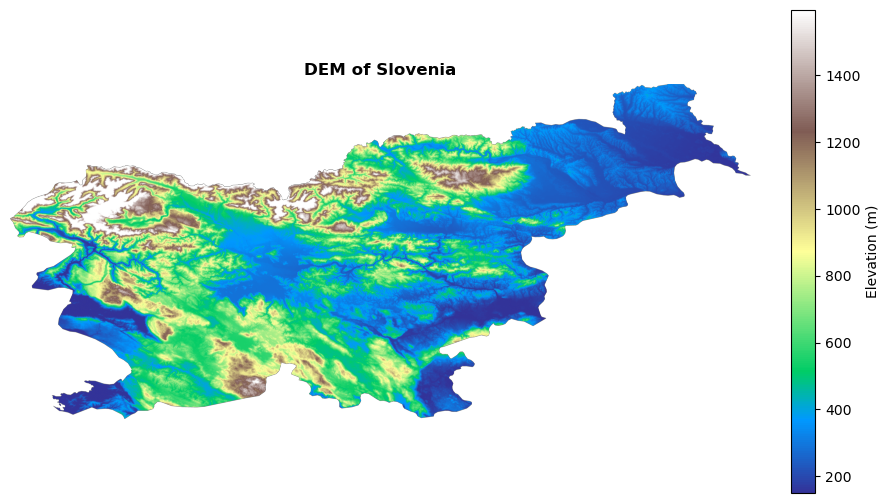

Saved dem_preview.png


In [8]:
clipped_dem = 'dem_clipped.tif'

with rasterio.open(DEM_PATH) as src:

    slov_reproj = slovenia.to_crs(src.crs)

    shapes = [g.__geo_interface__ for g in slov_reproj.geometry]

    out_img, out_tf = rio_mask(src, shapes, crop=True, nodata=-9999)

    meta = src.meta.copy()

    meta.update(driver='GTiff', 
                height=out_img.shape[1],
                width=out_img.shape[2],
                transform=out_tf, 
                nodata=-9999)
    
    with rasterio.open(clipped_dem, 
                       'w', 
                       **meta) as dst:
        
        dst.write(out_img)

with rasterio.open(clipped_dem) as src:

    dem_data = src.read(1, 
                        masked=True)
    
    print(f'Resolution : {src.res[0]:.0f} x {src.res[1]:.0f} m')

    print(f'Elevation  : {float(dem_data.min()):.0f} - {float(dem_data.max()):.0f} m')

fig, ax = plt.subplots(figsize=(9,6))

im = ax.imshow(dem_data, 
               cmap='terrain',
               vmin=float(np.nanpercentile(dem_data.compressed(),
                                           2)),
               vmax=float(np.nanpercentile(dem_data.compressed(),
                                           98)))

plt.colorbar(im, 
             ax=ax, 
             label='Elevation (m)', 
             fraction=0.03)

ax.set_title('DEM of Slovenia', 
             fontweight='bold'),

ax.axis('off'),

plt.tight_layout()

plt.savefig('dem_preview.png', 
            dpi=150, 
            bbox_inches='tight')

plt.show()

print('Saved dem_preview.png')


## Step 2: Zonal Statistics, Elevation per Flood Zone

In [ ]:
with rasterio.open(clipped_dem) as src:

    raster_crs = src.crs

flood_proj = flood_zones.to_crs(raster_crs)

stats = zonal_stats(flood_proj, 
                    clipped_dem,
                    stats=['mean',
                           'min',
                           'max',
                           'std'], 
                           nodata=-9999)

stats_df = pd.DataFrame(stats)

flood_zones = flood_zones.reset_index(drop=True)

flood_zones[['elev_mean',
             'elev_min',
             'elev_max',
             'elev_std']] = (
    stats_df[['mean',
              'min',
              'max',
              'std']]
)

print('Zonal stats sample (lowest-elevation flood zones):')
print(
    flood_zones[['flood_zone',
                 'return_period_yr',
                 'elev_mean','elev_min']]
    .dropna()
    .sort_values('elev_mean')
    .head(8)
    .round(1)
    .to_string(index=False)
)


Zonal stats sample (lowest-elevation flood zones):
     flood_zone  return_period_yr  elev_mean  elev_min
Drava — Maribor                10      167.3     150.0
Drava — Maribor                10      168.1     151.0
Drava — Maribor                10      173.3     143.0
Drava — Maribor               500      176.6     150.0
Drava — Maribor               500      183.6     160.0
 Savinja valley               100      243.8     173.0
Drava — Maribor                10      253.1     174.0
 Savinja valley                10      262.9     188.0


## Step 3: Spatial Join, Settlements Inside Flood Zones

In [ ]:
flood_3794  = flood_zones.to_crs('EPSG:3794')

settle_3794 = settlements.to_crs('EPSG:3794')

at_risk = gpd.sjoin(
    settle_3794,
    flood_3794[['geometry',
                'flood_zone',
                'return_period_yr',
                'elev_mean']],
    how='left',
    predicate='intersects'
)
at_risk['in_flood_zone'] = at_risk['index_right'].notna()

# keep highest-risk (lowest return period) match per settlement
at_risk_dedup = (
    at_risk.sort_values('return_period_yr')
           .groupby(level=0).first()
)
at_risk_dedup = as_gdf(at_risk_dedup)   # readd proper CRS 

n_risk  = int(at_risk_dedup['in_flood_zone'].sum())

n_total = len(at_risk_dedup)

print(f'Settlements directly in flood zones: {n_risk} / {n_total}  ({n_risk/n_total*100:.1f}%)')

print()

print(at_risk_dedup[at_risk_dedup.in_flood_zone]
      [['name','place','flood_zone','return_period_yr','elev_mean']]
      .head(10)
      .round(1)
      .to_string(index=False))


Settlements directly in flood zones: 99 / 4731  (2.1%)

                 name   place      flood_zone  return_period_yr  elev_mean
             Rapljevo village      Mura plain             100.0      463.3
               Žvirče village      Mura plain              10.0      492.8
               Višnje village      Mura plain              10.0      434.9
             Bezuljak village     Krka valley              10.0      798.2
           Gržeča vas village Drava — Maribor              10.0      167.3
               Drnovo village Drava — Maribor              10.0      173.3
Velika vas pri Krškem village Drava — Maribor              10.0      173.3
               Veniše village Drava — Maribor              10.0      173.3
                Ravno village Drava — Maribor             500.0      176.6
              Kržišče village Drava — Maribor             500.0      176.6


## Step 4: Risk Classification by Return Period

In [11]:
RISK_ORDER = [
    'Very High  (<=10 yr)',
    'High  (<=100 yr)',
    'Moderate  (<=500 yr)',
    'Proximity  (<=1 km)',
    'No hazard',
]

def classify_risk(row):

    if not row['in_flood_zone']:

        return 'No hazard'
    
    rp = row.get('return_period_yr', 100)

    if pd.isna(rp):   return 'Moderate  (<=500 yr)'

    if rp <= 10:      return 'Very High  (<=10 yr)'

    elif rp <= 100:   return 'High  (<=100 yr)'

    else:             return 'Moderate  (<=500 yr)'

at_risk_dedup['risk_level'] = at_risk_dedup.apply(classify_risk, 
                                                  axis=1)

print('Risk distribution (before buffer step):')

print(at_risk_dedup['risk_level'].value_counts().to_string())


Risk distribution (before buffer step):
risk_level
No hazard               4632
Very High  (<=10 yr)      53
High  (<=100 yr)          27
Moderate  (<=500 yr)      19


## Step 5: Buffer Analysis, 1 km Proximity Zone

In [12]:
flood_buffer_geom = flood_3794.geometry.buffer(1000).union_all()

flood_buffer_gdf  = gpd.GeoDataFrame(geometry=[flood_buffer_geom], 
                                     crs='EPSG:3794')

not_in_zone = as_gdf(at_risk_dedup[~at_risk_dedup.in_flood_zone]).copy()

not_in_zone = not_in_zone.drop(columns=['index_right'], 
                               errors='ignore')  

in_buffer     = gpd.sjoin(not_in_zone, 
                          flood_buffer_gdf, 
                          how='left', 
                          predicate='within')

proximity_ids = in_buffer[in_buffer['index_right'].notna()].index

at_risk_dedup.loc[proximity_ids, 
                  'risk_level'] = 'Proximity  (<=1 km)'

print('Risk distribution (after buffer step):')

print(at_risk_dedup['risk_level'].value_counts().reindex(RISK_ORDER).to_string())

n_prox = int((at_risk_dedup['risk_level'] == 'Proximity  (<=1 km)').sum())

print(f'\n{n_prox} additional settlements found within 1 km proximity zone')


Risk distribution (after buffer step):
risk_level
Very High  (<=10 yr)      53
High  (<=100 yr)          27
Moderate  (<=500 yr)      19
Proximity  (<=1 km)      103
No hazard               4529

103 additional settlements found within 1 km proximity zone


## Final Visualisation

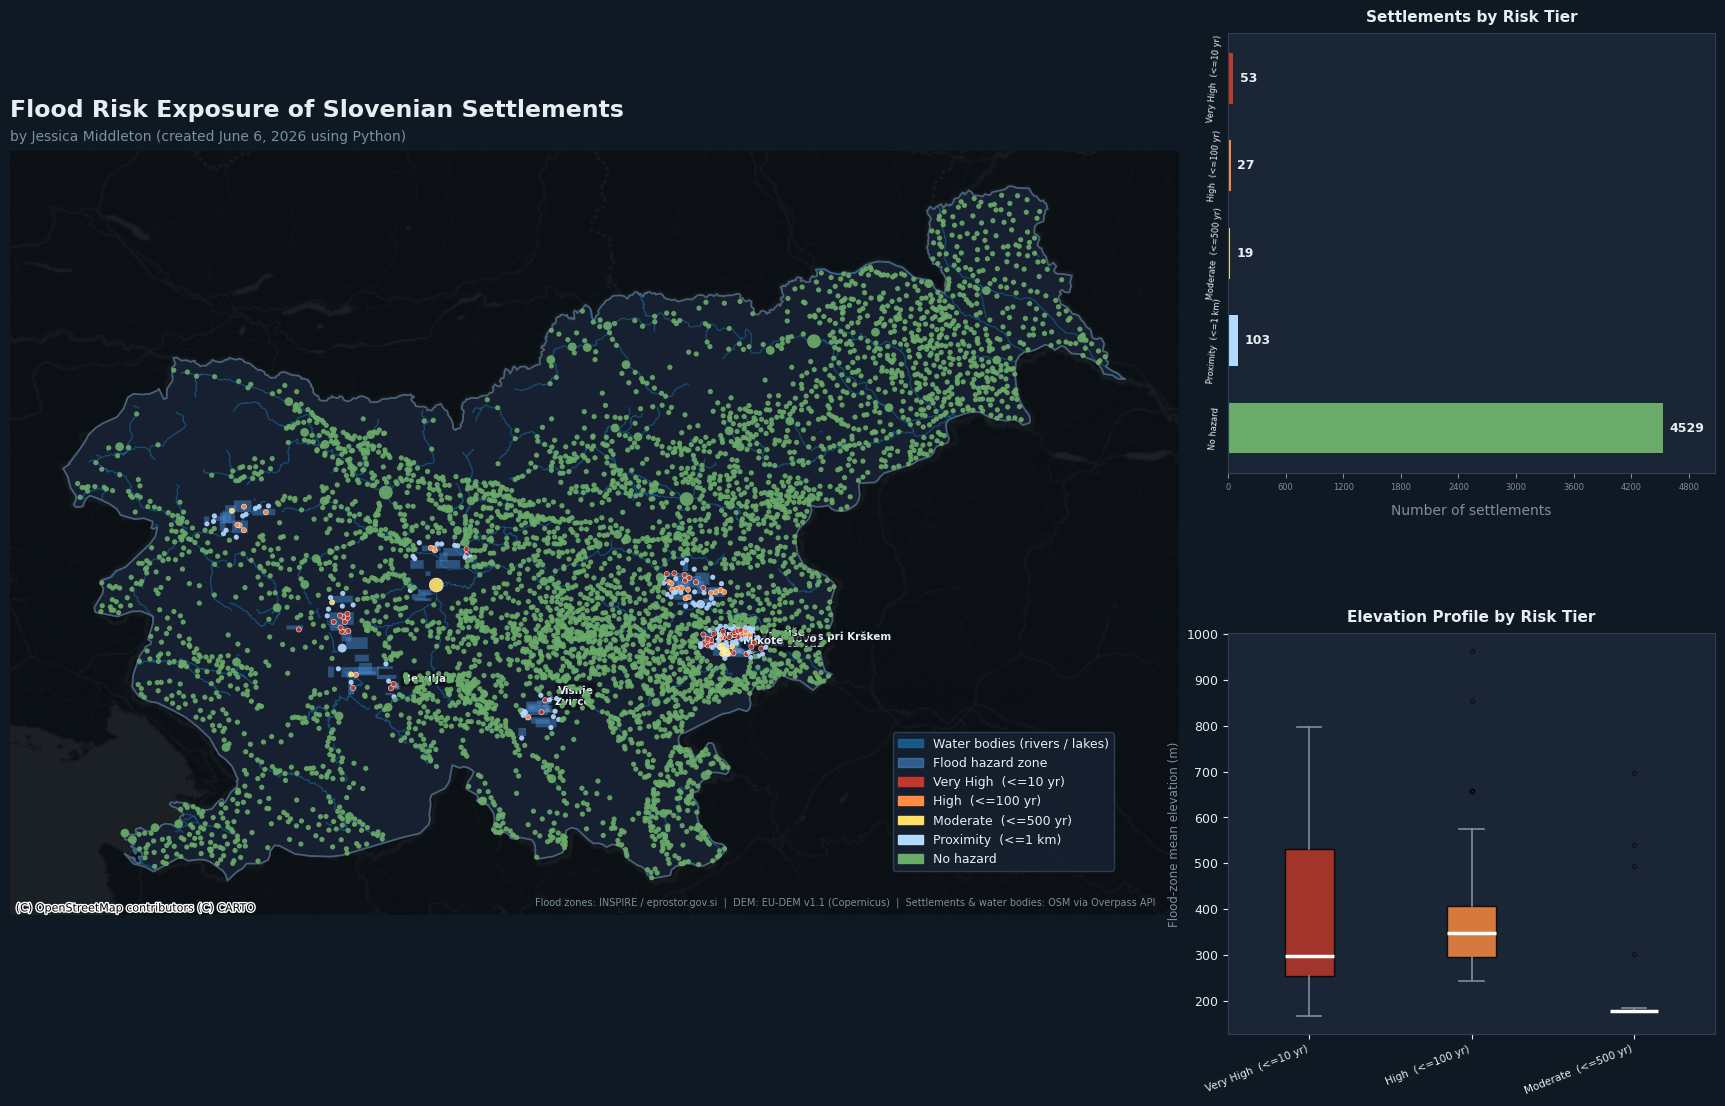

Saved slovenia_flood_risk_map.png


In [13]:
RISK_COLORS = {
    'Very High  (<=10 yr)': '#c0392b',
    'High  (<=100 yr)':     '#ff8c42',
    'Moderate  (<=500 yr)': '#ffe066',
    'Proximity  (<=1 km)':  '#b3d9ff',
    'No hazard':            '#6aab6a',
}

FLOOD_COLOR = '#4a90d9'

BG    = '#0f1923'

PANEL = '#1a2635'

TEXT  = '#e8edf2'

MUTED = '#7a8fa0'

fig = plt.figure(figsize=(22, 13), 
                 facecolor=BG)

gs  = gridspec.GridSpec(2, 
                        2, 
                        width_ratios=[2.4, 
                                      1],
                        height_ratios=[1.1, 
                                       1], 
                                       hspace=0.38, 
                                       wspace=0.06)

ax_map = fig.add_subplot(gs[:, 0])

ax_bar = fig.add_subplot(gs[0, 1])

ax_box = fig.add_subplot(gs[1, 1])

for ax in [ax_map, ax_bar, ax_box]:

    ax.set_facecolor(PANEL)

    ax.tick_params(colors=TEXT, labelsize=9)

    for sp in ax.spines.values():

        sp.set_edgecolor('#2e4058')

# Map (general)
slovenia.to_crs(3857).plot(ax=ax_map, 
                           color='#162030', 
                           edgecolor='#4a6278', 
                           linewidth=1.3)

# Water bodies layer mapping
WATER_COLOR = '#1a6fa8'

if len(water_bodies) > 0:

    wb_3857 = water_bodies.to_crs(3857)

    # Polygon water bodies (lakes, reservoirs)
    wb_poly = wb_3857[wb_3857.geometry.geom_type.isin(['Polygon', 
                                                       'MultiPolygon'])]
    
    if not wb_poly.empty:

        wb_poly.plot(ax=ax_map, 
                     color=WATER_COLOR, 
                     alpha=0.70,
                     edgecolor='none', 
                     zorder=2)
        
    # Linear waterways (rivers, canals)
    wb_line = wb_3857[wb_3857.geometry.geom_type.isin(['LineString', 
                                                       'MultiLineString'])]
    
    if not wb_line.empty:

        wb_line.plot(ax=ax_map, 
                     color=WATER_COLOR, 
                     alpha=0.55,
                     linewidth=0.9, 
                     zorder=2)

flood_3794.to_crs(3857).plot(ax=ax_map, 
                             color=FLOOD_COLOR, 
                             alpha=0.45, 
                             edgecolor='none', 
                             zorder=3)

settle_plot = as_gdf(at_risk_dedup).to_crs(3857)

size_map = {'city': 100, 
            'town': 40, 
            'village': 14}


for risk in RISK_ORDER:

    grp = settle_plot[settle_plot['risk_level'] == risk]

    if grp.empty: continue

    sizes = grp['place'].map(size_map).fillna(12)

    ec = 'white' if risk not in ('No hazard', 
                                 'Proximity  (<=1 km)') else 'none'
    
    grp.plot(ax=ax_map, 
             color=RISK_COLORS[risk], 
             markersize=sizes,
             alpha=0.92, 
             zorder=5, 
             edgecolors=ec, 
             linewidths=0.4)

# Label highest-risk settlements
risky = at_risk_dedup[at_risk_dedup['risk_level'].str.startswith(('Very High',
                                                                  'High'))].copy()

risky = as_gdf(risky).dropna(subset=['name'])

risky = risky.sort_values('return_period_yr').drop_duplicates('name').head(10)

for _, row in risky.to_crs(3857).iterrows():

    ax_map.annotate(
        row['name'],
        xy=(row.geometry.x, 
            row.geometry.y), 
            xytext=(9, 5),
        textcoords='offset points', 
        color=TEXT, 
        fontsize=7.5, 
        fontweight='bold',
        arrowprops=dict(arrowstyle='->', 
                        color=MUTED, 
                        lw=0.8),
        bbox=dict(boxstyle='round,pad=0.25', 
                  fc='#0a1018', 
                  ec='none', 
                  alpha=0.75)
    )

ctx.add_basemap(ax_map, 
                source=ctx.providers.CartoDB.DarkMatterNoLabels,
                    crs=3857, 
                    alpha=0.55)

ax_map.set_axis_off()

ax_map.set_title('Flood Risk Exposure of Slovenian Settlements',
                 color=TEXT, 
                 fontsize=17, 
                 fontweight='bold', 
                 pad=14, 
                 loc='left')

ax_map.text(
    0.0, 
    1.01,   
    'by Jessica Middleton (created June 6, 2026 using Python)', 
    transform=ax_map.transAxes,
    color=MUTED, 
    fontsize=10, 
    fontweight='regular',
    ha='left', 
    va='bottom'
)

ax_map.text(0.98, 
            0.01,
            'Flood zones: INSPIRE / eprostor.gov.si  |  DEM: EU-DEM v1.1 (Copernicus)  |'
            '  Settlements & water bodies: OSM via Overpass API',
            transform=ax_map.transAxes, 
            color=MUTED, 
            fontsize=7, 
            ha='right', 
            va='bottom')

patches  = [mpatches.Patch(color=WATER_COLOR, 
                           alpha=0.70, 
                           label='Water bodies (rivers / lakes)')]

patches += [mpatches.Patch(color=FLOOD_COLOR, 
                           alpha=0.55, 
                           label='Flood hazard zone')]

patches += [mpatches.Patch(color=RISK_COLORS[r], 
                           label=r) for r in RISK_ORDER]

ax_map.legend(handles=patches, 
              loc='lower right', 
              bbox_to_anchor=(0.95, 
                              0.05), 
                              fontsize=9,
              facecolor='#162030', 
              edgecolor='#2e4058',
              labelcolor=TEXT, 
              framealpha=0.92)





# Bar plot for settlements per risk tier
counts = at_risk_dedup['risk_level'].value_counts().reindex(RISK_ORDER).fillna(0)

colors_bar = [RISK_COLORS[r] for r in counts.index]

# Draw horizontal bars
bars = ax_bar.barh(counts.index, 
                   counts.values, 
                   color=colors_bar,
                   edgecolor='none', 
                   height=0.58)

# Invert Y-axis so the highest priority risk tier stays at the top
ax_bar.invert_yaxis()

# Set base tick parameters for both axes
ax_bar.tick_params(axis='y', 
                   colors=TEXT, 
                   labelsize=6, 
                   length=0, 
                   pad=10) 

ax_bar.tick_params(axis='x', 
                   colors=MUTED, 
                   labelsize=6)

# Force Y-axis labels to rotate 90° and center perfectly on their tick positions
for label in ax_bar.get_yticklabels():
    label.set_rotation(85)
    label.set_ha('center')
    label.set_va('center')

# Add values to the end of the bars 
offset = counts.max() * 0.015  
for bar, val in zip(bars, counts.values):
    if val > 0:
        ax_bar.text(val + offset, 
                    bar.get_y() + bar.get_height()/2,
                    f'{int(val)}', 
                    va='center', 
                    ha='left', 
                    color=TEXT, 
                    fontsize=9, 
                    fontweight='bold')

# Titles and Labels
ax_bar.set_title('Settlements by Risk Tier', 
                 color=TEXT, 
                 fontsize=11, 
                 fontweight='bold', 
                 pad=8)

# labelpad cleanly pushes the label below the numbers without breaking alignments
ax_bar.set_xlabel('Number of settlements', 
                  color=MUTED, 
                  fontsize=10, 
                  labelpad=8)

# Scale x-limit to accommodate the data text labels cleanly
ax_bar.set_xlim(0, counts.max() * 1.12)

ax_bar.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))





# Boxplot elevation distribution by tier 
elev_data = [
    at_risk_dedup.loc[at_risk_dedup['risk_level']==r, 'elev_mean'].dropna().values

    for r in RISK_ORDER
]

pairs = [(r, d) for r, d in zip(RISK_ORDER, elev_data) if len(d) > 0]

if pairs:
    labels_box, data_box = zip(*pairs)
    bp = ax_box.boxplot(data_box, 
                        vert=True, 
                        patch_artist=True,
                        medianprops=dict(color='white', 
                                         linewidth=2.5),
                        whiskerprops=dict(color=MUTED, 
                                          linewidth=1.2),
                        capprops=dict(color=MUTED, 
                                      linewidth=1.2),
                        flierprops=dict(marker='o', 
                                        color=MUTED, 
                                        markersize=3, 
                                        alpha=0.5))
    
    for patch, lbl in zip(bp['boxes'], labels_box):

        patch.set_facecolor(RISK_COLORS.get(lbl, '#888'))

        patch.set_alpha(0.82)

    ax_box.set_xticklabels(labels_box, 
                           rotation=22, 
                           ha='right', 
                           fontsize=7.5, 
                           color=TEXT)
    
    ax_box.set_ylabel('Flood-zone mean elevation (m)', 
                      color=MUTED, 
                      fontsize=8.5)
    
    ax_box.set_title('Elevation Profile by Risk Tier', 
                     color=TEXT,
                     fontsize=11, 
                     fontweight='bold', 
                     pad=8)
    
    ax_box.yaxis.set_tick_params(labelcolor=TEXT)


plt.savefig('slovenia_flood_risk_map.png', 
            dpi=200, 
            bbox_inches='tight', 
            facecolor=BG)

plt.show()

print('Saved slovenia_flood_risk_map.png')

## Summary

In [14]:
total   = len(at_risk_dedup)
in_zone = int(at_risk_dedup['in_flood_zone'].sum())
in_prox = int((at_risk_dedup['risk_level'] == 'Proximity  (<=1 km)').sum())
vhigh   = int(at_risk_dedup['risk_level'].str.startswith('Very High').sum())
high    = int(at_risk_dedup['risk_level'].str.startswith('High').sum())

at_elev   = at_risk_dedup[at_risk_dedup.in_flood_zone]['elev_mean'].mean()
safe_elev = at_risk_dedup[~at_risk_dedup.in_flood_zone]['elev_mean'].mean()

rows = [
    ('Total settlements analysed',           total),
    ('  Inside flood hazard zone',           in_zone),
    ('  Within 1 km proximity buffer',       in_prox),
    ('  Very High risk (<=10 yr return)',     vhigh),
    ('  High risk (<=100 yr return)',         high),
    ('Flood hazard polygons (input)',         len(flood_zones)),
    ('Mean elevation - at-risk (m)',         f'{at_elev:.0f}' if pd.notna(at_elev) else 'n/a'),
    ('Mean elevation - no hazard (m)',       f'{safe_elev:.0f}' if pd.notna(safe_elev) else 'n/a'),
]

print('  SUMMARY: Slovenia Flood Risk Analysis')
for lbl, val in rows:
    print(f'  {lbl:<42} {val}')


  SUMMARY: Slovenia Flood Risk Analysis
  Total settlements analysed                 4731
    Inside flood hazard zone                 99
    Within 1 km proximity buffer             103
    Very High risk (<=10 yr return)          53
    High risk (<=100 yr return)              27
  Flood hazard polygons (input)              70
  Mean elevation - at-risk (m)               368
  Mean elevation - no hazard (m)             n/a
